### Import bibliotek

In [29]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

### Wczytanie danych

In [15]:
iris = load_iris()
x = iris.data
y = iris.target
df = pd.DataFrame(x, columns=['Długość działki[cm]', 'Szerokość działki[cm]', 'Długość płatka[cm]', 'Szerokość płatka[cm]'])
df['gatunek'] = y

### Analiza danych

In [16]:
print("Liczba wierszy: ", df.shape[0])
print("Liczba cech: ", df.shape[1])
print("Podział na klasy:\n", df['gatunek'].value_counts())
print("Pierwsze 5 danych:\n", df.head())

Liczba wierszy:  150
Liczba cech:  5
Podział na klasy:
 gatunek
0    50
1    50
2    50
Name: count, dtype: int64
Pierwsze 5 danych:
    Długość działki[cm]  Szerokość działki[cm]  Długość płatka[cm]  \
0                  5.1                    3.5                 1.4   
1                  4.9                    3.0                 1.4   
2                  4.7                    3.2                 1.3   
3                  4.6                    3.1                 1.5   
4                  5.0                    3.6                 1.4   

   Szerokość płatka[cm]  gatunek  
0                   0.2        0  
1                   0.2        0  
2                   0.2        0  
3                   0.2        0  
4                   0.2        0  


### Normalizacja

In [17]:
print("Średnie kolumn przed standaryzacją:\n", np.mean(x, axis=0))
print("Odchylenia standardowe kolumn przed standaryzacją:\n", np.std(x, axis=0))
x_srednia = np.mean(x, axis=0)
x_odchylenie_standardowe = np.std(x, axis=0)
x_ustandaryzowane = (x - x_srednia) / x_odchylenie_standardowe
print("Średnie kolumn po standaryzacji:\n", np.mean(x_ustandaryzowane, axis=0))
print("Odchylenia standardowe kolumn po standaryzacji:\n", np.std(x_ustandaryzowane, axis=0))

Średnie kolumn przed standaryzacją:
 [5.84333333 3.05733333 3.758      1.19933333]
Odchylenia standardowe kolumn przed standaryzacją:
 [0.82530129 0.43441097 1.75940407 0.75969263]
Średnie kolumn po standaryzacji:
 [-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]
Odchylenia standardowe kolumn po standaryzacji:
 [1. 1. 1. 1.]


### Utworzenie neuronów

In [18]:
neurony = np.random.randn(3, 4)

### Implementacja odległości

In [19]:
def oblicz_odleglosci(kwiatek, neurony):
    odleglosci_d = np.sqrt(np.sum((neurony - kwiatek) ** 2, axis=1))
    return odleglosci_d

### Znalezienie neuronu zwycięskiego

In [20]:
def znajdz_zwyciezce(kwiatek, neurony):
    indeks_zwyciezcy = np.argmin(oblicz_odleglosci(kwiatek, neurony))
    return indeks_zwyciezcy

### Implementacja aktualizacji wag

In [21]:
def przybliz_neuron(kwiatek, neurony, indeks_zwyciezcy, krok):
    neurony[indeks_zwyciezcy] = neurony[indeks_zwyciezcy] + krok * (kwiatek - neurony[indeks_zwyciezcy])
    return neurony

### Ostateczna funkcja uproszczonego algorytmu SOM
Zastosowania z lab'u 2:
- zmniejszanie współczynnika uczenia w miarę trwania algorytmu
- wyświetlanie wartości współczynnika co 10 epok

In [22]:
def algorytm_som(przyklady, neurony, tempo_uczenia, liczba_epok):
    T = liczba_epok
    while liczba_epok != 0:
        tempo = tempo_uczenia * (liczba_epok / T)

        if liczba_epok % 10 == 0:
            print("Wartość współczynnika: ", tempo)

        for przyklad in przyklady:
            zwyciezca = znajdz_zwyciezce(przyklad, neurony)
            neurony = przybliz_neuron(przyklad, neurony, zwyciezca, tempo)

        liczba_epok -= 1

    return neurony

## SOM pod eksperymenty

In [23]:
def trenuj_som(X, y, liczba_neuronow=3, tempo_uczenia=0.5, liczba_epok=100, tasowanie=True, seed=42):
    rng = np.random.default_rng(seed)
    neurony = rng.standard_normal((liczba_neuronow, X.shape[1]))
    start = time.perf_counter()

    for epoka in range(liczba_epok):
        tempo = tempo_uczenia * ((liczba_epok - epoka) / liczba_epok)
        indeksy = rng.permutation(len(X)) if tasowanie else np.arange(len(X))
        for indeks in indeksy:
            przyklad = X[indeks]
            zwyciezca = znajdz_zwyciezce(przyklad, neurony)
            neurony[zwyciezca] += tempo * (przyklad - neurony[zwyciezca])

    czas_ms = (time.perf_counter() - start) * 1000

    przypisania = np.array([znajdz_zwyciezce(k, neurony) for k in X])

    # średnia odległość próbki od jej zwycięzcy
    odleglosci = [oblicz_odleglosci(X[i], neurony)[przypisania[i]] for i in range (len(X))]
    srednia_odleglosc = float(np.mean(odleglosci))

    # jak dobrze neurony rozdzielają gatunki
    liczba_klas = len(np.unique(y))
    macierz = np.zeros((liczba_neuronow, liczba_klas), dtype=int)
    for klasa, neuron in zip(y, przypisania):
        macierz[neuron, klasa] += 1
    purity = float(np.sum(np.max(macierz, axis=1)) / len(y))

    # martwe neurony
    martwe_neurony = int(np.sum(np.sum(macierz, axis=1) == 0))

    return {
        "neurony": neurony,
        "macierz": macierz,
        "QE": round(srednia_odleglosc, 4),
        "Purity": round(purity * 100, 2),
        "Martwe_neurony": martwe_neurony,
        "Czas_ms": round(czas_ms, 2)
    }

In [24]:
def uruchom_eksperyment(nazwa_parametru, wartosci, **bazowe):
    wyniki = []
    for wartosc in wartosci:
        parametry = bazowe.copy()
        parametry[nazwa_parametru] = wartosc
        res = trenuj_som(x_ustandaryzowane, y, **parametry)
        wyniki.append({
            nazwa_parametru: wartosc,
            "QE": res["QE"],
            "Purity [%]": res["Purity"],
            "Martwe neurony": res["Martwe_neurony"],
            "Czas [ms]": res["Czas_ms"]
        })
    return pd.DataFrame(wyniki)

## Eksperymenty wykorzystane w sprawozdaniu

In [25]:
baza = dict(liczba_neuronow=3, tempo_uczenia = 0.5, liczba_epok=100, tasowanie=True, seed=42)
print("=== 1. Wpływ liczby neuronów ===")
display(uruchom_eksperyment("liczba_neuronow", [2, 3, 5, 10, 15], **baza))
print("=== 2. Wpływ tempa uczenia ===")
display(uruchom_eksperyment("tempo_uczenia", [0.01, 0.1, 0.5, 0.9], **baza))
print("=== 3. Wpływ liczby epok ===")
display(uruchom_eksperyment("liczba_epok", [10, 50, 100, 500, 1000], **baza))
print("=== 4. Wpływ tasowania danych ===")
display(uruchom_eksperyment("tasowanie", [False, True], **baza))

=== 1. Wpływ liczby neuronów ===


,liczba_neuronow,QE,Purity [%],Martwe neurony,Czas [ms]
0,2,1.0601,66.67,0,405.72
1,3,0.8604,83.33,0,382.89
2,5,0.6967,83.33,0,308.39
3,10,0.5636,91.33,1,304.78
4,15,0.4523,94.67,2,302.76


=== 2. Wpływ tempa uczenia ===


,tempo_uczenia,QE,Purity [%],Martwe neurony,Czas [ms]
0,0.01,0.8602,83.33,0,304.99
1,0.10,0.8605,83.33,0,287.43
2,0.50,0.8604,83.33,0,280.41
3,0.90,0.8601,83.33,0,276.87


=== 3. Wpływ liczby epok ===


,liczba_epok,QE,Purity [%],Martwe neurony,Czas [ms]
0,10,0.8661,83.33,0,38.04
1,50,0.8593,83.33,0,149.52
2,100,0.8604,83.33,0,304.40
3,500,0.8604,83.33,0,1424.23
4,1000,0.8602,83.33,0,2730.12


=== 4. Wpływ tasowania danych ===


,tasowanie,QE,Purity [%],Martwe neurony,Czas [ms]
0,False,0.8610,82.67,0,302.24
1,True,0.8604,83.33,0,281.03


## Wykresy eksperymentów
Wykres nr 1. Wypływ liczby neuronów na QE i Purity

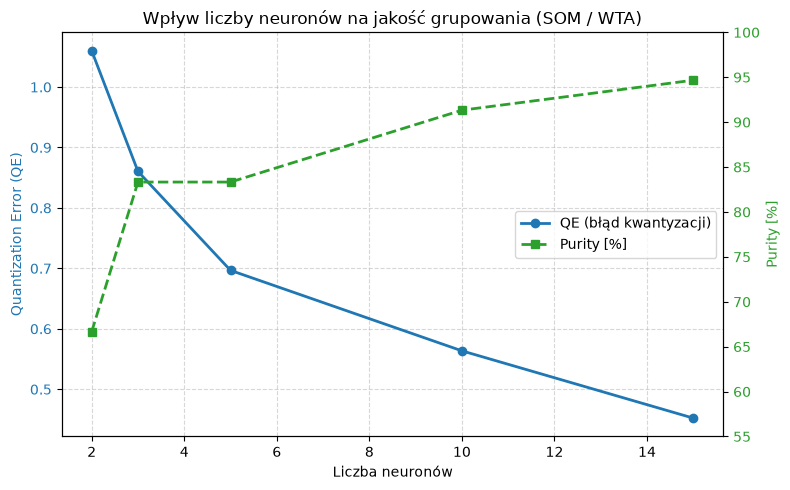

In [30]:
df_neurony = uruchom_eksperyment("liczba_neuronow", [2, 3, 5, 10, 15], **baza)

fig, ax1 = plt.subplots(figsize=(8, 5))

kolor_qe = 'tab:blue'
ax1.set_xlabel('Liczba neuronów')
ax1.set_ylabel('Quantization Error (QE)', color=kolor_qe)
l1 = ax1.plot(df_neurony['liczba_neuronow'], df_neurony['QE'],
              marker='o', linewidth=2, color=kolor_qe, label='QE (błąd kwantyzacji)')
ax1.tick_params(axis='y', labelcolor=kolor_qe)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
kolor_pur = 'tab:green'
ax2.set_ylabel('Purity [%]', color=kolor_pur)
l2 = ax2.plot(df_neurony['liczba_neuronow'], df_neurony['Purity [%]'],
              marker='s', linewidth=2, linestyle='--', color=kolor_pur, label='Purity [%]')
ax2.tick_params(axis='y', labelcolor=kolor_pur)
ax2.set_ylim(55, 100)

linie = l1 + l2
etykiety = [l.get_label() for l in linie]
ax1.legend(linie, etykiety, loc='center right')
plt.title('Wpływ liczby neuronów na jakość grupowania (SOM / WTA)')
plt.tight_layout()
plt.show()

Wykres nr 2. Pozycje wytrenowanych neuronów w przestrzeni cech

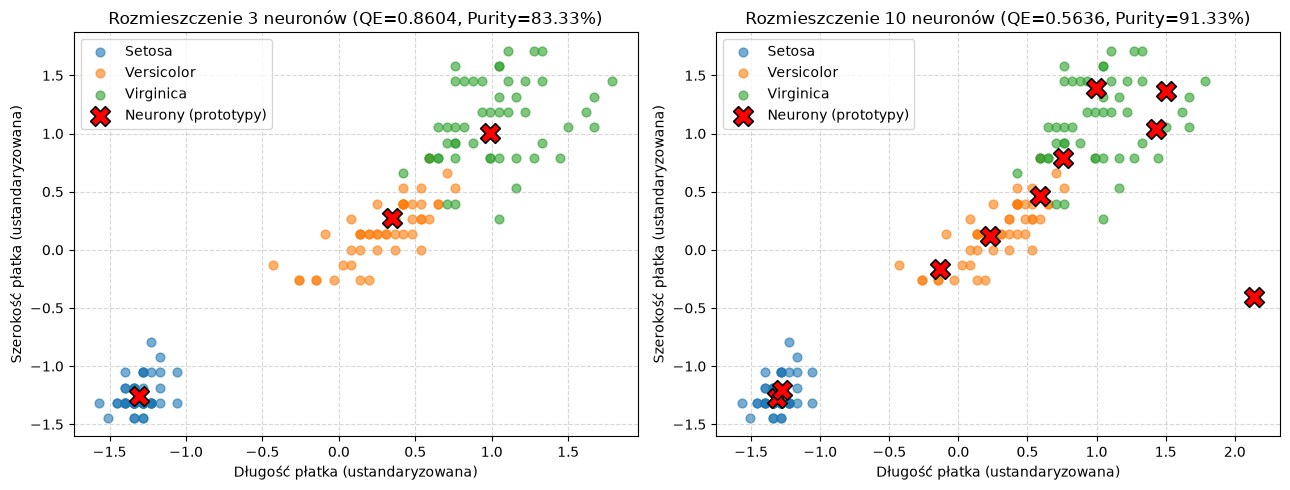

In [31]:
fig, osie = plt.subplots(1, 2, figsize=(13, 5))
nazwy_klas = ['Setosa', 'Versicolor', 'Virginica']
kolory_klas = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, n_neu in zip(osie, [3, 10]):
    res = trenuj_som(x_ustandaryzowane, y, liczba_neuronow=n_neu,
                     tempo_uczenia=0.5, liczba_epok=100, tasowanie=True, seed=42)
    wagi = res['neurony']

    for klasa in range(3):
        maska = (y == klasa)
        ax.scatter(x_ustandaryzowane[maska, 2], x_ustandaryzowane[maska, 3],
                   c=kolory_klas[klasa], label=nazwy_klas[klasa], alpha=0.6, s=40)

    ax.scatter(wagi[:, 2], wagi[:, 3], c='red', marker='X', s=200,
               edgecolors='black', linewidths=1.2, label='Neurony (prototypy)', zorder=5)

    ax.set_title(f'Rozmieszczenie {n_neu} neuronów (QE={res["QE"]}, Purity={res["Purity"]}%)')
    ax.set_xlabel('Długość płatka (ustandaryzowana)')
    ax.set_ylabel('Szerokość płatka (ustandaryzowana)')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

### Testy
Zgodnie z poleceniem w lab'ie 2-gim:
- przypisanie przykładów do każdego neuronu

In [26]:
wytrenowane_neurony = algorytm_som(x_ustandaryzowane, neurony.copy(), tempo_uczenia=0.5, liczba_epok=100)
przypisane_etykiety = [znajdz_zwyciezce(kwiatek, wytrenowane_neurony) for kwiatek in x_ustandaryzowane]
ilosci_elementow = {0: 0, 1: 0, 2: 0}
for etykieta in przypisane_etykiety:
    ilosci_elementow[etykieta] += 1

print("WYNIKI UCZENIA ALGORYTMEM SOM")
print("Rozkład kwiatków w grupach:")
for neuron_i, ilosc in ilosci_elementow.items():
    print(f"Neuron {neuron_i + 1} zgrupował {ilosc} sztuk")
print("\nOstateczne wagi neuronów (pozycje w 4-wymiarowej przestrzeni):")
print(np.round(wytrenowane_neurony, 2))

Wartość współczynnika:  0.5
Wartość współczynnika:  0.45
Wartość współczynnika:  0.4
Wartość współczynnika:  0.35
Wartość współczynnika:  0.3
Wartość współczynnika:  0.25
Wartość współczynnika:  0.2
Wartość współczynnika:  0.15
Wartość współczynnika:  0.1
Wartość współczynnika:  0.05
WYNIKI UCZENIA ALGORYTMEM SOM
Rozkład kwiatków w grupach:
Neuron 1 zgrupował 46 sztuk
Neuron 2 zgrupował 54 sztuk
Neuron 3 zgrupował 50 sztuk

Ostateczne wagi neuronów (pozycje w 4-wymiarowej przestrzeni):
[[ 1.15  0.09  1.02  1.07]
 [-0.04 -0.87  0.38  0.33]
 [-1.02  0.84 -1.3  -1.25]]


### [LAB 2] Macierz rozkładu przykładów

In [27]:
macierz_wynikow = np.zeros((3, 3), dtype=int)
for nazwa_gatunku, przypisany_neuron in zip(y, przypisane_etykiety):
    macierz_wynikow[przypisany_neuron][nazwa_gatunku] += 1
print("\nMacierz rozkładu przykładów")
print("Neuron | Setosa | Versicolor | Virginica")
print("-" * 45)
for i in range(3):
    print(f"N{i+1}     | {macierz_wynikow[i][0]}     | {macierz_wynikow[i][1]}         | {macierz_wynikow[i][2]}")



Macierz rozkładu przykładów
Neuron | Setosa | Versicolor | Virginica
---------------------------------------------
N1     | 0     | 11         | 35
N2     | 0     | 39         | 15
N3     | 50     | 0         | 0
